# Analyze Little Washita Geometries

Explore the static grid, layer thicknesses, and spatial inputs for a selected Little Washita run. Runs are read from `LW_Runs/<run_name>`; input PFBs are read from that run folder when present, otherwise from `model_inputs`.

## 1. Select a run and load grid information

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from parflow import Run
from parflow.tools.io import read_pfb

# Choose a completed run inside LW_Runs.
run_name = "LW_CLM"
run_dir = os.path.join(os.getcwd(), "LW_Runs", run_name)
input_dir = os.path.join(os.getcwd(), "model_inputs")
run_definition = os.path.join(run_dir, f"{run_name}.pfidb")

if not os.path.isfile(run_definition):
    raise FileNotFoundError(f"Run definition not found: {run_definition}")

run = Run.from_definition(run_definition)
data = run.data_accessor
nz, ny, nx = data.shape
dx, dy = data.dx, data.dy
dz = np.asarray(data.dz, dtype=float)
if dz.size != nz:
    raise ValueError(f"Expected {nz} layer thicknesses, found {dz.size}")

def input_file(file_name):
    for directory in (run_dir, input_dir):
        path = os.path.join(directory, file_name)
        if os.path.isfile(path):
            return path
    raise FileNotFoundError(f"Could not find {file_name} in {run_dir} or {input_dir}")

mask_input = read_pfb(input_file("LW.mask.pfb"))[0, :, :]
domain_mask_2d = mask_input > 0
if domain_mask_2d.shape != (ny, nx):
    raise ValueError(f"Mask shape {domain_mask_2d.shape} does not match the run grid {(ny, nx)}")
domain_mask_3d = np.broadcast_to(domain_mask_2d, (nz, ny, nx))
x_edges = np.arange(nx + 1) * dx
y_edges = np.arange(ny + 1) * dy
z_edges = np.concatenate(([0.0], np.cumsum(dz)))

print(f"Run: {run_name}")
print(f"Grid: nx={nx}, ny={ny}, nz={nz}; dx={dx}, dy={dy}")
print(f"Vertical thicknesses (bottom to top): {dz}")

Solver: Field BinaryOutDir is not part of the expected schema <class 'parflow.tools.database.generated.Solver'>
  - nc
  - nr
  - nt
  - sw_ini
  - qflx_tran_vegm
  - scalez
  - hkdepth
  - wtfact
  - trsmx0
  - smpmax
  - pondmx
  - sdep
  - manning
  - rout
  - cout
  - sovout
Run: LW_CLM
Grid: nx=64, ny=32, nz=10; dx=1000.0, dy=1000.0
Vertical thicknesses (bottom to top): [1.0e+03 1.0e+02 5.0e+01 2.5e+01 1.0e+01 5.0e+00 1.0e+00 6.0e-01 3.0e-01
 1.0e-01]


## 2. Domain mask and computational grid

The plan view shows active and inactive cells with individual grid-cell boundaries overlaid.

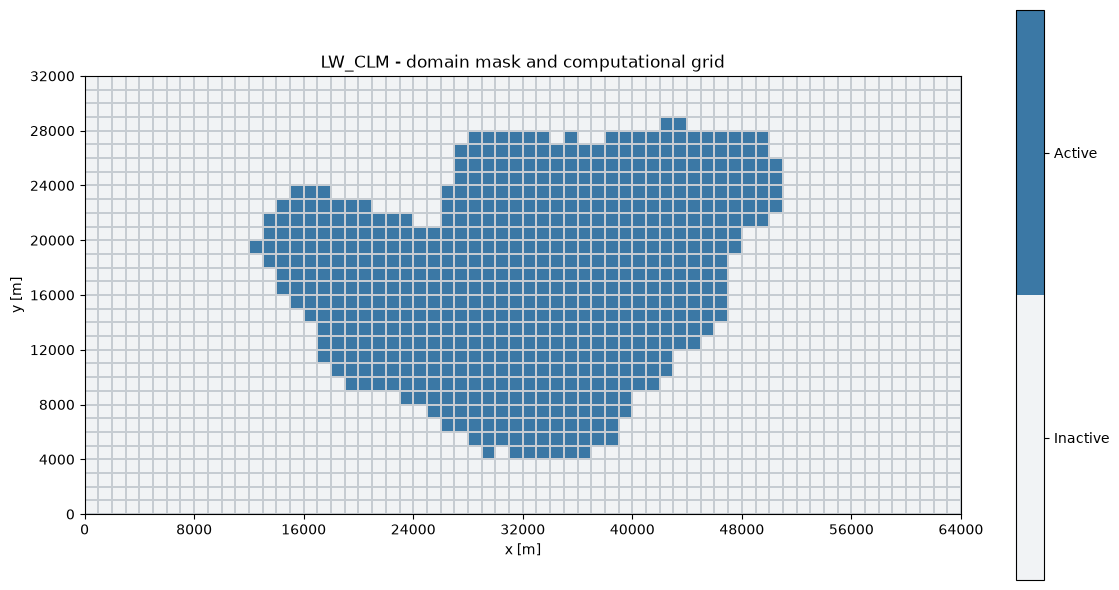

In [2]:
mask_cmap = ListedColormap(["#f1f3f5", "#3b78a5"])
fig, ax = plt.subplots(figsize=(12, 6))
mask_plot = ax.pcolormesh(
    x_edges,
    y_edges,
    domain_mask_2d.astype(int),
    shading="flat",
    cmap=mask_cmap,
    vmin=0,
    vmax=1,
    edgecolors="#c6ccd2",
    linewidth=0.15,
)
mask_colorbar = fig.colorbar(mask_plot, ax=ax, ticks=[0.25, 0.75])
mask_colorbar.set_ticklabels(["Inactive", "Active"])
ax.set_title(f"{run_name} - domain mask and computational grid")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_xticks(np.arange(0, nx + 1, 8) * dx)
ax.set_yticks(np.arange(0, ny + 1, 4) * dy)
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## 3. Variable vertical layer thickness

Layer 0 is the bottom of the model. The cell prints each layer thickness and shows one vertical column at true cumulative height.

Layer thicknesses (layer 0 = bottom):
Layer 0: 1000 m
Layer 1: 100 m
Layer 2: 50 m
Layer 3: 25 m
Layer 4: 10 m
Layer 5: 5 m
Layer 6: 1 m
Layer 7: 0.6 m
Layer 8: 0.3 m
Layer 9: 0.1 m


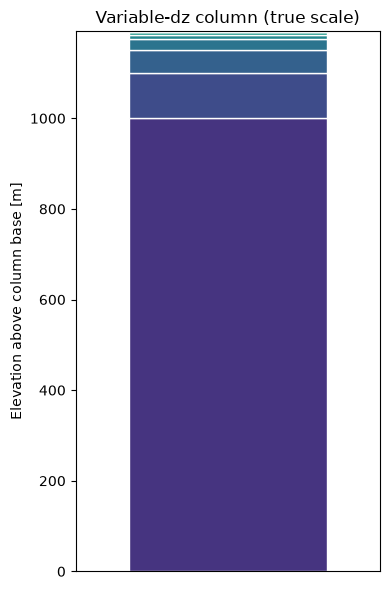

In [5]:
layers = np.arange(nz)
layer_colors = plt.get_cmap("viridis")(np.linspace(0.15, 0.85, nz))
print("Layer thicknesses (layer 0 = bottom):")
for layer, thickness in enumerate(dz):
    print(f"Layer {layer}: {thickness:g} m")

fig, ax_column = plt.subplots(figsize=(4, 6))
ax_column.bar(
    np.full(nz, 0.5),
    dz,
    bottom=z_edges[:-1],
    width=0.65,
    color=layer_colors,
    edgecolor="white",
)
ax_column.set_xlim(0, 1)
ax_column.set_ylim(0, z_edges[-1])
ax_column.set_xticks([])
ax_column.set_ylabel("Elevation above column base [m]")
ax_column.set_title("Variable-dz column (true scale)")
fig.tight_layout()
plt.show()

## 4. Select a 3D field and inspect layers and a cross-section

Choose a name from the printed list by setting `selected_3d_variable`. The layer panels use one shared color scale. Set `cross_section_axis` to `x` or `y` and edit `cross_section_index` to choose the fixed grid index: `x` shows a y-z slice, while `y` shows an x-z slice. The vertical axis uses equally spaced layer numbers (0 = bottom), not variable-dz height.

Available 3D fields:
Computed porosity
Computed permeability X
Computed permeability Y
Computed permeability Z
Specific storage
Indicator field


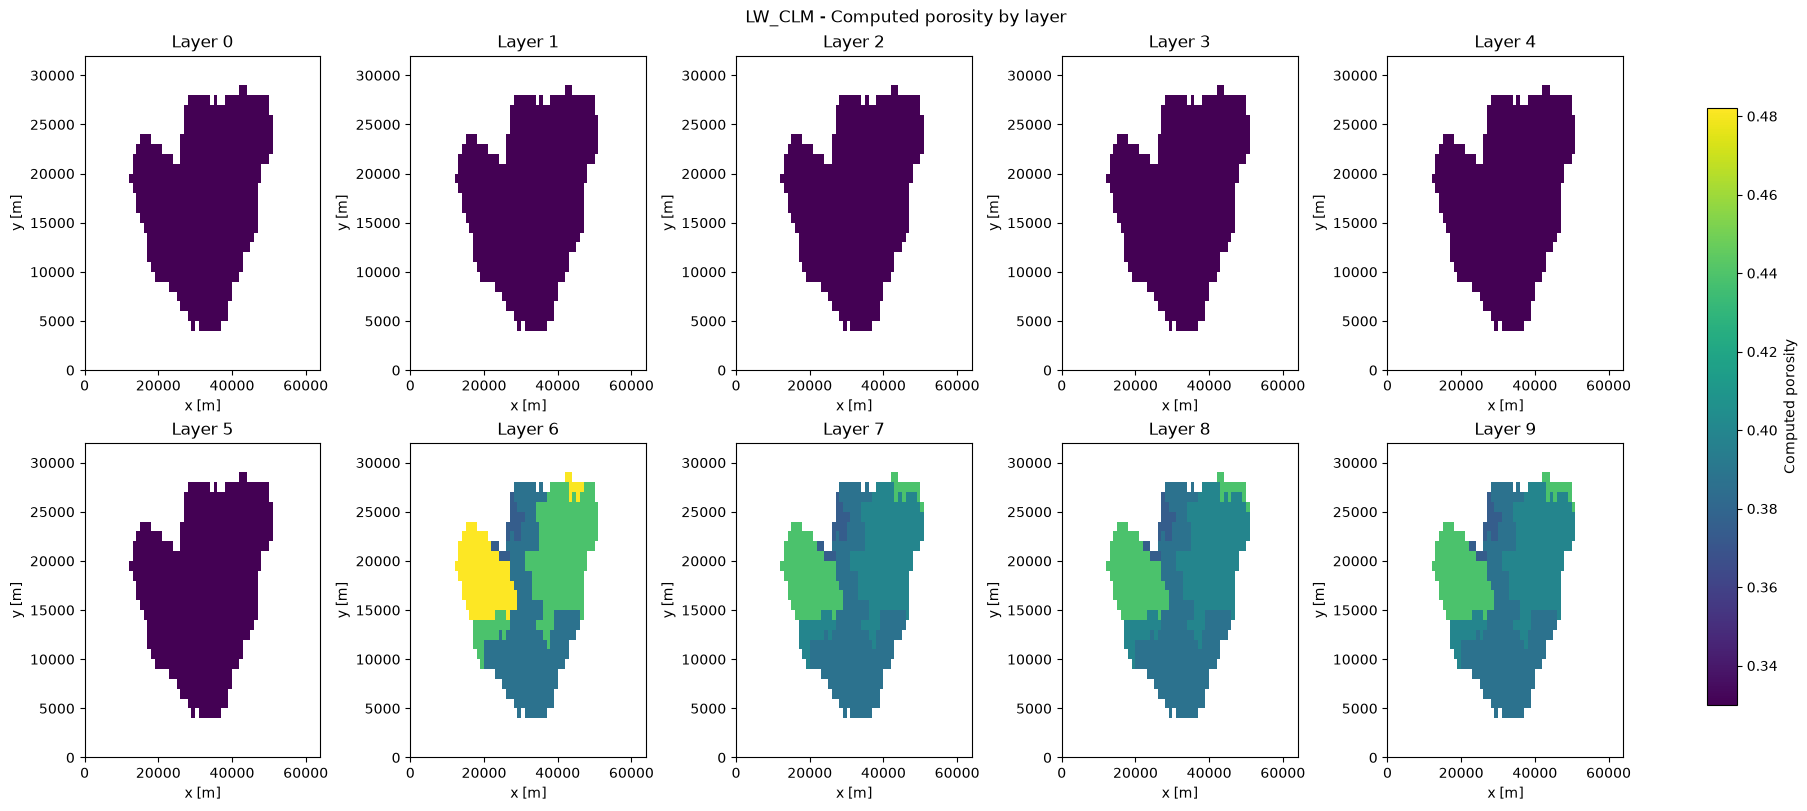

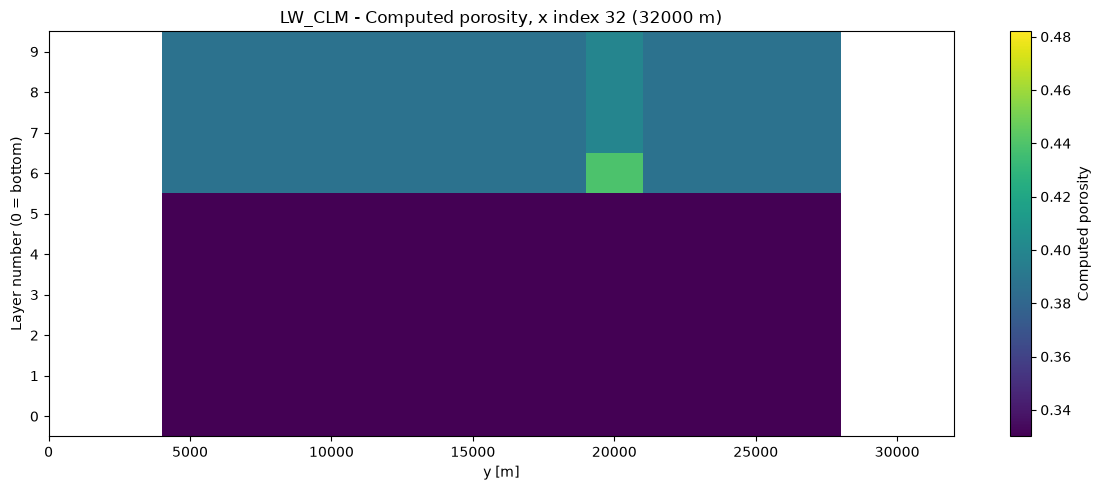

In [6]:
three_d_options = {
    "Computed porosity": lambda: data.computed_porosity,
    "Computed permeability X": lambda: data.computed_permeability_x,
    "Computed permeability Y": lambda: data.computed_permeability_y,
    "Computed permeability Z": lambda: data.computed_permeability_z,
    "Specific storage": lambda: data.specific_storage,
    "Indicator field": lambda: read_pfb(input_file("Indicator_LW_USGS_Bedrock.pfb"))
}
print("Available 3D fields:")
print("\n".join(three_d_options))

# Select one of the names printed above.
selected_3d_variable = "Computed porosity"
if selected_3d_variable not in three_d_options:
    raise ValueError(f"Choose one of: {list(three_d_options)}")

field = np.asarray(three_d_options[selected_3d_variable](), dtype=float)
if field.shape != (nz, ny, nx):
    raise ValueError(f"{selected_3d_variable} has shape {field.shape}; expected {(nz, ny, nx)}")
field[np.abs(field) > 1e30] = np.nan
if selected_3d_variable != "Domain mask":
    field = np.where(domain_mask_3d, field, np.nan)
valid_values = field[np.isfinite(field)]
if valid_values.size == 0:
    raise ValueError(f"{selected_3d_variable} has no finite values inside the domain")
vmin, vmax = float(valid_values.min()), float(valid_values.max())
if vmin == vmax:
    padding = max(abs(vmin) * 1e-6, 1e-12)
    vmin, vmax = vmin - padding, vmax + padding

fig, axes = plt.subplots(2, 5, figsize=(18, 8), constrained_layout=True)
for layer, ax in enumerate(axes.flat):
    image = ax.imshow(
        field[layer],
        origin="lower",
        extent=(0, nx * dx, 0, ny * dy),
        aspect="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(f"Layer {layer}")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
fig.suptitle(f"{run_name} - {selected_3d_variable} by layer")
fig.colorbar(image, ax=axes.ravel().tolist(), label=selected_3d_variable, shrink=0.85)
plt.show()

# Choose the fixed coordinate as an array index.
cross_section_axis = "x"
cross_section_index = nx // 2 if cross_section_axis == "x" else ny // 2
if cross_section_axis == "x":
    if not 0 <= cross_section_index < nx:
        raise IndexError(f"x index must be between 0 and {nx - 1}")
    section = field[:, :, cross_section_index]
    section_mask = domain_mask_3d[:, :, cross_section_index]
    horizontal_edges = y_edges
    horizontal_label = "y [m]"
    location_label = f"x index {cross_section_index} ({cross_section_index * dx:g} m)"
elif cross_section_axis == "y":
    if not 0 <= cross_section_index < ny:
        raise IndexError(f"y index must be between 0 and {ny - 1}")
    section = field[:, cross_section_index, :]
    section_mask = domain_mask_3d[:, cross_section_index, :]
    horizontal_edges = x_edges
    horizontal_label = "x [m]"
    location_label = f"y index {cross_section_index} ({cross_section_index * dy:g} m)"
else:
    raise ValueError("cross_section_axis must be 'x' or 'y'")

section_plot = np.ma.masked_where(~section_mask, section)
layer_edges = np.arange(nz + 1)
fig, ax = plt.subplots(figsize=(12, 5))
section_image = ax.pcolormesh(
    horizontal_edges,
    layer_edges,
    section_plot,
    shading="flat",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
)
ax.set_title(f"{run_name} - {selected_3d_variable}, {location_label}")
ax.set_xlabel(horizontal_label)
ax.set_yticks(np.arange(nz) + 0.5)
ax.set_yticklabels([str(layer) for layer in range(nz)])
ax.set_ylim(0, nz)
ax.set_ylabel("Layer number (0 = bottom)")
fig.colorbar(section_image, ax=ax, label=selected_3d_variable)
fig.tight_layout()
plt.show()

## 5. Plot 2D inputs

This cell plots Manning's roughness input and the x- and y-direction topographic slopes.

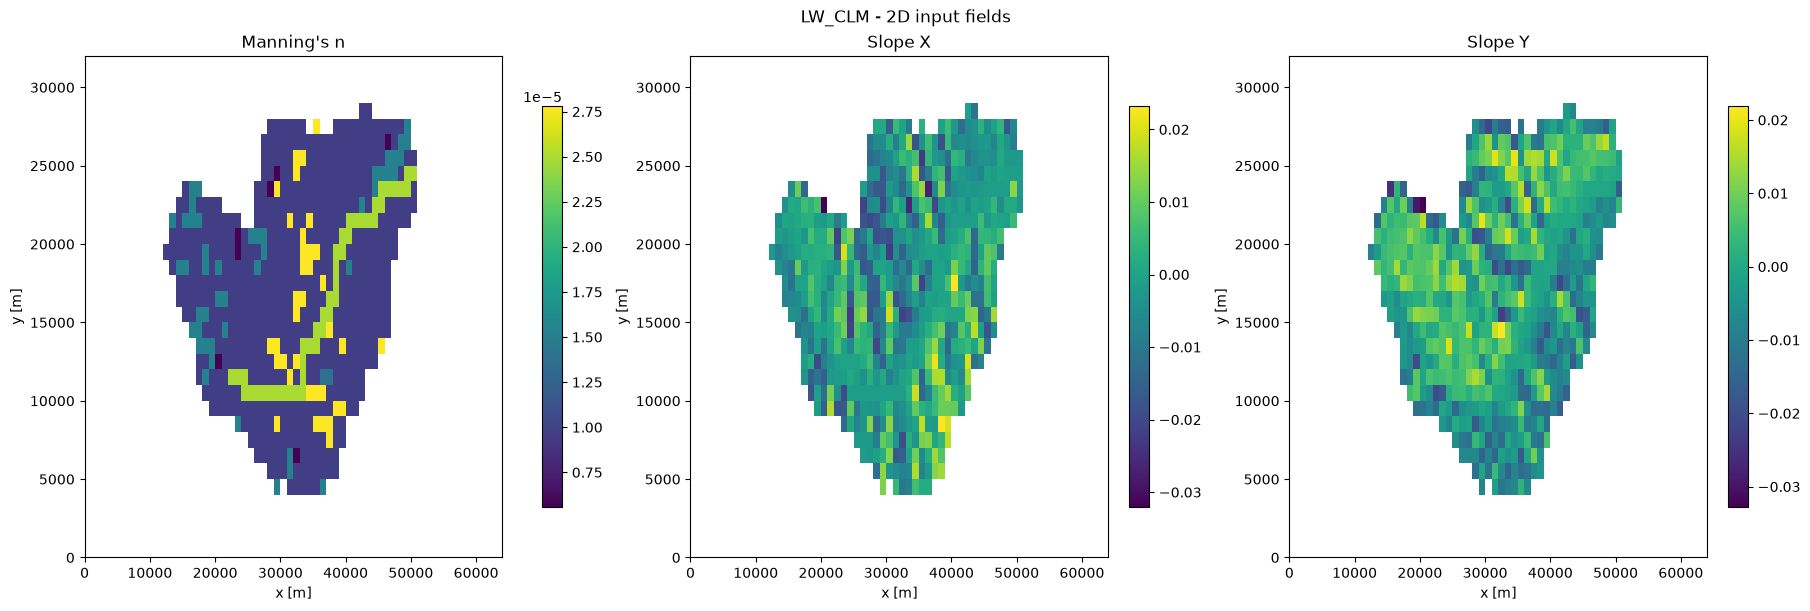

In [7]:
two_d_inputs = {
    "Manning's n": ("Manning_CONUS2.0_LW.pfb", "Manning's n"),
    "Slope X": ("slopex_LW.pfb", "Slope X"),
    "Slope Y": ("slopey_LW.pfb", "Slope Y"),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, (variable, (file_name, title)) in zip(axes, two_d_inputs.items()):
    values = np.asarray(read_pfb(input_file(file_name))[0], dtype=float)
    if values.shape != (ny, nx):
        raise ValueError(f"{file_name} has shape {values.shape}; expected {(ny, nx)}")
    values[np.abs(values) > 1e30] = np.nan
    values = np.where(domain_mask_2d, values, np.nan)
    image = ax.imshow(
        values,
        origin="lower",
        extent=(0, nx * dx, 0, ny * dy),
        aspect="auto",
        cmap="viridis",
    )
    ax.set_title(title)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    fig.colorbar(image, ax=ax, shrink=0.8)
fig.suptitle(f"{run_name} - 2D input fields")
plt.show()